In [5]:
import pandas as pd

In [6]:
file1 = "coconut_candidates_positive_np_score.csv"
file2 = "results_sorted.xlsx"
df1 = pd.read_csv(file1)
df2 = pd.read_excel(file2)
df1["CNP_ID"] = df1["CNP_ID"].astype(str).str.strip()
df2["CNP_ID"] = df2["CNP_ID"].astype(str).str.strip()

merged = pd.merge(df1,df2,left_on= "CNP_ID",right_on="CNP_ID",how="inner")


In [7]:
final_df = merged[
    [
        "COCONUT_IDENTIFIER",
        'CNP_ID',
        'SMILES',
        'Mean_Active_Probability',
        "Docking_Score"
    ]]

final_df.to_csv("final_compounds.csv", index= False)
print(f"Number of matched compounds: {len(final_df)}")
final_df.head(5)

Number of matched compounds: 109


,COCONUT_IDENTIFIER,CNP_ID,SMILES,Mean_Active_Probability,Docking_Score
0,CNP0159688.3,CNP0159688,Nc1nc(Cl)nc2c1ncn2[C@H]1O[C@H](CO)[C@@H](O)[C@...,0.765756,-6.577\t
1,CNP0159688.2,CNP0159688,Nc1nc(Cl)nc2c1ncn2[C@@H]1O[C@H](CO)[C@@H](O)[C...,0.765756,-6.577\t
2,CNP0159688.1,CNP0159688,Nc1nc(Cl)nc2c1ncn2[C@@H]1O[C@H](CO)[C@H](O)[C@...,0.765756,-6.577\t
3,CNP0332379.1,CNP0332379,Nc1ncnc2ncn([C@@H]3O[C@@H](CO)[C@@H](O)[C@@H]3...,0.754448,-6.801\t
4,CNP0512390.1,CNP0512390,Nc1ccnc2c1ncn2[C@@H]1O[C@H](CO)[C@@H](O)[C@H]1O,0.754448,-6.379\t


In [1]:
pip install pandas openpyxl seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


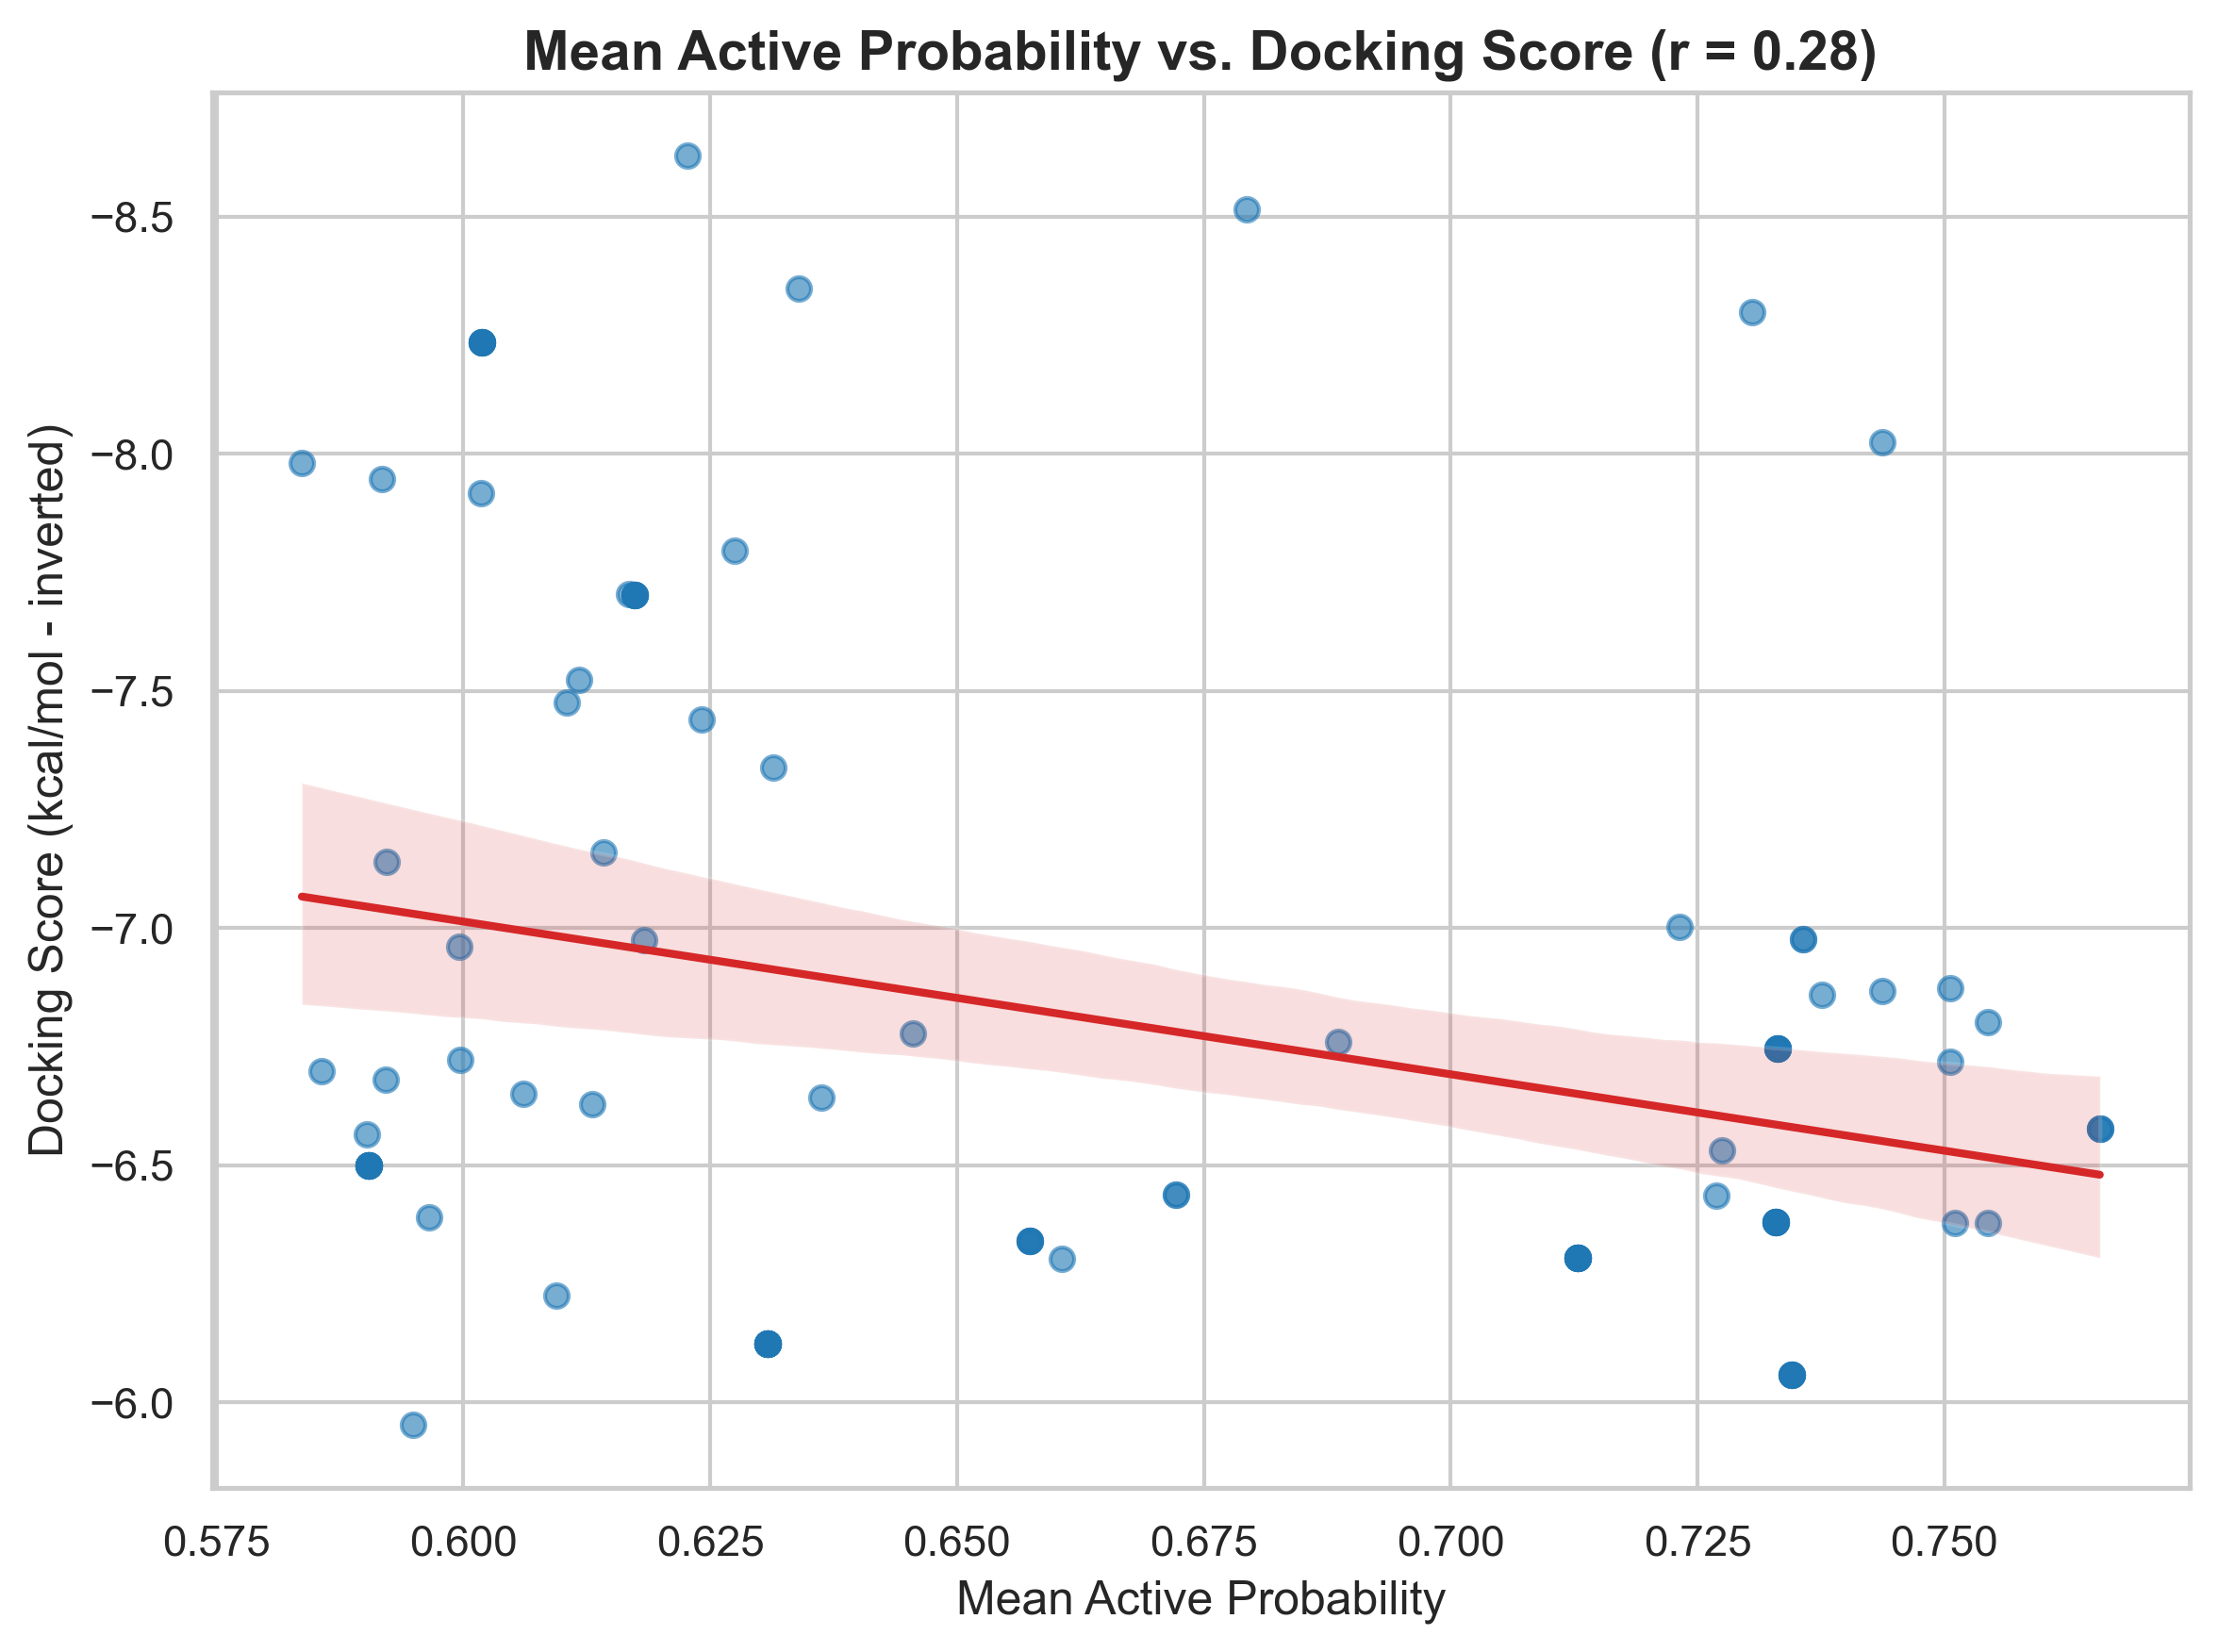

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('final_compounds.csv')

col_x = 'Mean_Active_Probability'
col_y = 'Docking_Score'

# Fix: Convert columns to numeric, replacing string/garbage values with NaN
df[col_x] = pd.to_numeric(df[col_x], errors='coerce')
df[col_y] = pd.to_numeric(df[col_y], errors='coerce')

# Drop missing or non-numeric rows
df_clean = df.dropna(subset=[col_x, col_y])

# Calculate Pearson correlation coefficient
corr_value = df_clean[col_x].corr(df_clean[col_y])

# Set plot style
sns.set_theme(style='whitegrid')
plt.figure(figsize=(8, 6), dpi =300)

# Plot scatter points with linear regression line
sns.regplot(
    data=df_clean, 
    x=col_x, 
    y=col_y, 
    scatter_kws={'alpha': 0.6, 'color': '#1f77b4'}, 
    line_kws={'color': '#d62728', 'linewidth': 2}
)

# Invert Y-axis for docking scores
plt.gca().invert_yaxis()

plt.title(f'Mean Active Probability vs. Docking Score (r = {corr_value:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Mean Active Probability', fontsize=12)
plt.ylabel('Docking Score (kcal/mol - inverted)', fontsize=12)

plt.tight_layout()
plt.savefig('correlation_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
from scipy import stats

# Calculate Pearson correlation coefficient and p-value
r_val, p_val = stats.pearsonr(df_clean[col_x], df_clean[col_y])

print(f"Pearson r: {r_val:.3f}")
print(f"p-value:   {p_val:.3e}")

if p_val < 0.05:
    print("The correlation is statistically significant (p < 0.05).")
else:
    print("No statistically significant linear relationship detected (p >= 0.05).")

Pearson r: 0.281
p-value:   3.190e-03
The correlation is statistically significant (p < 0.05).
